# WakeWise NL: wake-aware wind-turbine siting for Newfoundland's west coast with QAOA

**Team AI Entanglers** · Qiskit Fall Fest 2026, Memorial University · Theme: *Quantum for a Sustainable Newfoundland and Labrador*

**Question.** On a wind parcel next to Wreckhouse, which candidate sites should get a turbine so the farm delivers the most net clean energy once the turbines' wakes (the slower air behind each rotor) are accounted for?

**Why quantum.** Every wake loss is between a *pair* of turbines, so the siting problem is a quadratic binary optimization (QUBO). It maps one-to-one onto an Ising Hamiltonian: each site is a qubit, each turbine's value is a $Z$ field, and each wake interaction is a $ZZ$ coupling. We solve it with QAOA in Qiskit and compare against exact enumeration, a greedy planner and random guessing on the *same* instances.

**Results at a glance** (details and the hardware run in Sections 6 and 8):

* Real data: 8,740 hours of 2025 Wreckhouse wind; one 4 MW turbine alone yields about 14,000 MWh/yr, and a single badly placed neighbour costs up to 4.4% of that.
* Classical: on the 12-site parcel the exact optimum builds 6 turbines; a greedy planner misses 9.6% of the achievable net energy (5.9% on 9 sites).
* Quantum, noiseless simulation (12 qubits): QAOA at p=3 returns the optimal layout in 1.26% of shots, about 50x random guessing, so 236 shots find it with 95% confidence versus 12,269 for random guessing.
* Quantum, realistic IBM Heron noise model (9 qubits): the signal survives (gap closed 0.39 to 0.51 versus 0.44 to 0.57 noiseless); dropping weak couplings cuts two-qubit gates from 144 to 64 at p=1.
* Model check: the pairwise QUBO ranks layouts almost exactly like a richer multi-wake model (Spearman 0.99).
* No quantum advantage is claimed: at 9 to 12 sites a laptop solves the problem exactly, which is precisely what lets us measure QAOA's quality honestly.

## 0. Reproducibility (read first)

| Item | Details |
|---|---|
| Environment | Python 3.12 virtual environment; exact package versions are printed in the next cell and pinned in `requirements.txt`. Developed on macOS (Apple silicon). |
| Setup and run | `git clone https://github.com/mrw-soumik/Qiskit-AI-Entanglers-.git && cd Qiskit-AI-Entanglers-`<br>`python3.12 -m venv .venv && source .venv/bin/activate && pip install -r requirements.txt`<br>`python test_wakewise.py` (self-checks)<br>`jupyter nbconvert --to notebook --execute --inplace wakewise.ipynb` (about 3 minutes, **no IBM account needed**) |
| Input data | `data/wreckhouse_2025_hourly.csv`: Environment and Climate Change Canada hourly wind at Wreckhouse, NL (climate ID 8404343), all of 2025, Open Government Licence (Canada). Source URL and retrieval time in `data/SOURCE.md`; regenerate with `wakewise.fetch_wind()`. Preparation: drop hours with a missing value; convert km/h to m/s; extrapolate 10 m to the 110 m hub with a power-law shear profile ($\alpha = 0.14$). |
| Seeds and sampling | COBYLA (SciPy), `maxiter=300`, 5 starting points drawn with NumPy seed 7. Ideal sampling: `StatevectorSampler(seed=11)`, 10,000 shots. Noisy simulation: `FakeFez` (IBM Heron r2 noise model) with `seed_simulator=42`, 4,000 shots. Transpiler: preset pass manager, `optimization_level=3`, `seed_transpiler=1`. |
| Baseline and evaluation | Section 3 computes the exact optimum (all $2^n$ layouts), the greedy planner and the uniform-random control. Every sampled layout, quantum or classical, is scored with the same full QUBO via `wakewise.summarize`. |
| Hardware | `RUN_HARDWARE` is off by default and the notebook loads `results/hardware_9site.json` (device, job ID, shots, error-suppression options, calibration snapshot, transpiled two-qubit gate counts, raw counts). To rerun on IBM hardware: copy `.env.example` to `.env`, add your API key and instance CRN, then run with `RUN_HARDWARE=1`. |
| Simulator vs hardware | Sections 5 and 7 are noiseless simulation. Section 6 separates noiseless simulation, noisy simulation (`FakeFez`) and real hardware in different columns. |

**What is real and what is assumed**

| Input | Status |
|---|---|
| Hourly wind direction and speed, Wreckhouse 2025 | **Observed** (ECCC) |
| Hub-height extrapolation ($\alpha=0.14$) | Assumption (standard open-terrain value) |
| Turbine: 4 MW, 130 m rotor, generic power curve, thrust coefficient 0.8 | Illustrative (not a specific product) |
| Jensen/Park wake model, decay constant 0.075 | Standard engineering model; pairwise superposition is an approximation checked in Section 7 |
| Parcel: flat grid, 5 rotor diameters (650 m) apart | Illustrative |
| Costs expressed as energy: 88% of a turbine's free-stream output + 2% per 650 m of cable to the substation | Illustrative (sensitivity tested in Section 3) |

In [1]:
import os, sys, json, platform, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import qiskit, qiskit_aer, qiskit_ibm_runtime, scipy
import wakewise as ww

warnings.filterwarnings("ignore", category=UserWarning)  # local simulators note that DD/twirling options don't apply
print(f"Python {sys.version.split()[0]} | {platform.system()} {platform.machine()}")
print(f"qiskit {qiskit.__version__} | qiskit-aer {qiskit_aer.__version__} | qiskit-ibm-runtime {qiskit_ibm_runtime.__version__} "
      f"| numpy {np.__version__} | scipy {scipy.__version__} | pandas {pd.__version__}")

RUN_HARDWARE = os.environ.get("RUN_HARDWARE") == "1"     # default: load saved hardware results
SEED_STARTS, SEED_SAMPLER, SEED_NOISE = 7, 11, 42
SHOTS_IDEAL, SHOTS_DEVICE = 10_000, 4_000
FIG = ww.ROOT / "figures"; FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "axes.spines.top": False, "axes.spines.right": False})

Python 3.12.4 | Darwin arm64
qiskit 2.6.2 | qiskit-aer 0.18.2 | qiskit-ibm-runtime 0.51.0 | numpy 2.5.4 | scipy 1.18.1 | pandas 3.1.1


## 1. The problem, why it matters in Newfoundland and Labrador, and the sustainability benefit

**Local relevance.** Wreckhouse, on the island's southwest coast between Cape Ray and St. Andrew's, is famous for south-easterly gales strong enough to have blown railway cars off the tracks ([Wreckhouse](https://en.wikipedia.org/wiki/Wreckhouse,_Newfoundland_and_Labrador)). The neighbouring Codroy Valley and the Port au Port Peninsula are where World Energy GH2's *Project Nujio'qonik* proposes wind farms (at least 150 turbines) to power a hydrogen and ammonia plant in Stephenville; the province released it from environmental assessment, with conditions, in April 2024 ([NL Government bulletin](https://www.gov.nl.ca/releases/2024/ecc-en/0409n05/), [CBC](https://www.cbc.ca/news/canada/newfoundland-labrador/wegh2-environment-approval-1.7168450)). MUN's NSERC CREATE-SWIFT program, presented at this Fall Fest, explicitly calls for wind-energy optimization benchmarks that compare classical and quantum or hybrid methods.

**Decision.** Which of $n$ candidate sites on a parcel get a turbine ($x_i = 1$) or not ($x_i = 0$).

**Intended use of the output.** Early-stage layout screening: a ranked set of layouts and the energy at stake, before detailed engineering. Not a construction recommendation.

**Sustainability benefit.** Turbines placed in each other's wakes waste wind: in this data a single badly placed neighbour costs up to about 4% of a turbine's annual output, and losses add up across a farm. Choosing layouts that keep more energy per turbine means more clean electricity (or green hydrogen) from the same land, steel and concrete, or the same energy from fewer turbines and less disturbed ground. The prototype demonstrates the *decision method* on a small idealized parcel; the real-world benefit would come from applying it with site-specific terrain, turbines and costs.

**Objective (QUBO, energy units of MWh per year, lower is better)**

$$f(x) = -\sum_i (E - c_i)\,x_i \;+\; \sum_{i<j} W_{ij}\,x_i x_j$$

* $E$: annual energy of one turbine standing alone, from the real hourly wind and the power curve.
* $c_i$: annualized cost of a turbine at site $i$, expressed as energy (base cost plus cable to the substation at site 0).
* $W_{ij}$: annual energy lost when both $i$ and $j$ are built ($i$ shading $j$ plus $j$ shading $i$), from the Jensen wake model applied hour by hour.

Every bitstring is a valid layout, so there are no penalty terms to tune.

## 2. Data: one year of hourly wind at Wreckhouse

8740 hourly records in 2025, 8740 usable (missing direction or speed dropped)
mean speed: 6.71 m/s at 10 m  ->  9.38 m/s at the 110 m hub; calm hours: 1.7%; hours above 25 m/s cut-out at hub: 2.4%


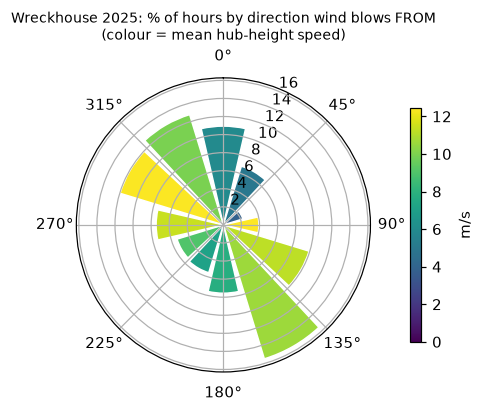

In [2]:
wd, u = ww.load_wind()
raw = pd.read_csv(ww.DATA / "wreckhouse_2025_hourly.csv")
u10 = u / (ww.TURBINE["hub"] / 10) ** 0.14
print(f"{len(raw)} hourly records in 2025, {len(u)} usable (missing direction or speed dropped)")
print(f"mean speed: {u10.mean():.2f} m/s at 10 m  ->  {u.mean():.2f} m/s at the 110 m hub; "
      f"calm hours: {(u == 0).mean():.1%}; hours above 25 m/s cut-out at hub: {(u >= 25).mean():.1%}")

sector = ((wd + 15) % 360 // 30).astype(int)
freq = np.bincount(sector, minlength=12) / len(sector)
mean_speed = np.array([u[sector == s].mean() for s in range(12)])
fig = plt.figure(figsize=(4.6, 4.6))
ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
bars = ax.bar(np.radians(np.arange(12) * 30), freq * 100, width=np.radians(26),
              color=plt.cm.viridis(mean_speed / mean_speed.max()), edgecolor="white")
ax.set_title("Wreckhouse 2025: % of hours by direction wind blows FROM\n(colour = mean hub-height speed)", fontsize=9)
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(0, mean_speed.max()))
fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.1, label="m/s")
fig.savefig(FIG / "wind_rose.png", bbox_inches="tight"); plt.show()

The wind is strongly bimodal: south-easterlies (the Wreckhouse gales) and north-westerlies dominate. Turbines lined up along that SE-NW axis will shade each other most, which is exactly the structure the QUBO has to capture.

## 3. Classical model and baselines

Two instances on a flat grid with 650 m (5 rotor diameter) spacing:

* **Main instance:** 3 x 4 grid, 12 sites (12 qubits), used for all noiseless experiments.
* **Hardware instance:** 3 x 3 grid, 9 sites (9 qubits), small enough for meaningful results on today's noisy hardware.

In [3]:
spacing = 5 * ww.TURBINE["D"]
inst = {}
for name, (rows, cols) in {"main_12": (3, 4), "hw_9": (3, 3)}.items():
    xy = ww.grid(rows, cols, spacing)
    lin, W, info = ww.build_qubo(xy, wd, u)
    x_opt, f_opt, values = ww.exact(lin, W)
    x_gr = ww.greedy(lin, W)
    inst[name] = dict(xy=xy, rows=rows, cols=cols, lin=lin, W=W, E=info["E"], x_opt=x_opt, f_opt=f_opt,
                      values=values, f_rand=values.mean(), x_gr=x_gr, f_gr=ww.qubo_values(x_gr, lin, W)[0])

E = inst["main_12"]["E"]
print(f"free-stream energy per turbine E = {E:,.0f} MWh/yr (capacity factor {E / (4 * 8760):.0%})")
iu = np.triu_indices(12, 1)
Wm = inst["main_12"]["W"][iu]
print(f"wake couplings (12 sites): {np.count_nonzero(Wm)} of {len(Wm)} pairs, largest {Wm.max():,.0f} MWh/yr "
      f"({Wm.max() / E:.1%} of E), median {np.median(Wm):,.0f} MWh/yr")

rows = []
for name, d in inst.items():
    n = len(d["lin"])
    rows.append({"instance": name, "sites (qubits)": n, "layouts": 2 ** n,
                 "exact optimum f*": round(d["f_opt"]), "turbines in optimum": int(d["x_opt"].sum()),
                 "greedy f": round(d["f_gr"]), "greedy gap": f"{(d['f_gr'] - d['f_opt']) / abs(d['f_opt']):.1%}",
                 "random mean f": round(d["f_rand"])})
baseline_table = pd.DataFrame(rows).set_index("instance")
baseline_table

free-stream energy per turbine E = 13,993 MWh/yr (capacity factor 40%)
wake couplings (12 sites): 66 of 66 pairs, largest 613 MWh/yr (4.4% of E), median 111 MWh/yr


,sites (qubits),layouts,exact optimum f*,turbines in optimum,greedy f,greedy gap,random mean f
instance,,,,,,,
main_12,12,4096,-5105,6,-4617,9.6%,-3087
hw_9,9,512,-4718,5,-4437,5.9%,-3106


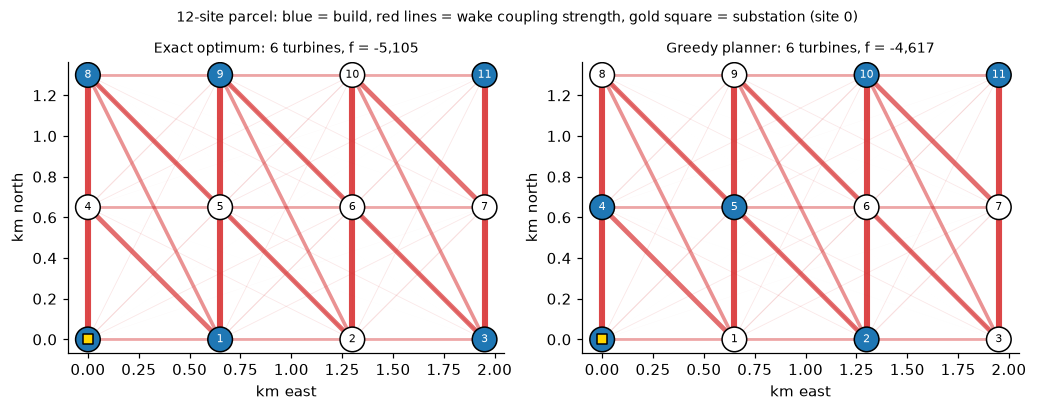

In [4]:
def draw_layout(ax, d, x, title):
    xy = d["xy"] / 1000
    W = d["W"]
    for i, j in zip(*np.triu_indices(len(xy), 1)):
        if W[i, j] > 0:
            ax.plot(*xy[[i, j]].T, color="tab:red", alpha=0.85 * W[i, j] / W.max(), lw=4 * W[i, j] / W.max(), zorder=1)
    ax.scatter(*xy.T, s=260, c=["tab:blue" if b else "white" for b in x], edgecolors="black", zorder=2)
    for k, (px, py) in enumerate(xy):
        ax.annotate(str(k), (px, py), ha="center", va="center", fontsize=7, color="white" if x[k] else "black", zorder=3)
    ax.scatter(*xy[0], marker="s", s=40, c="gold", edgecolors="black", zorder=4)
    ax.set_title(title, fontsize=9); ax.set_aspect("equal"); ax.set_xlabel("km east"); ax.set_ylabel("km north")

d = inst["main_12"]
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.6))
draw_layout(axs[0], d, d["x_opt"], f"Exact optimum: {int(d['x_opt'].sum())} turbines, f = {d['f_opt']:,.0f}")
draw_layout(axs[1], d, d["x_gr"], f"Greedy planner: {int(d['x_gr'].sum())} turbines, f = {d['f_gr']:,.0f}")
fig.suptitle("12-site parcel: blue = build, red lines = wake coupling strength, gold square = substation (site 0)", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "layouts.png", bbox_inches="tight"); plt.show()

**Why not just sort or use a greedy rule?** Greedy adds the best site one at a time and never revisits a choice, so it locks in turbines that later block better combinations. On the real Wreckhouse wind it misses the optimum by the gap shown above. The interactions are what make the problem hard, and they are what QAOA encodes.

**Sensitivity to the illustrative cost assumption.** The cost level decides how many turbines are worth building; the optimization is non-trivial across the range.

In [5]:
sens = []
for frac in [0.80, 0.88, 0.93]:
    lin_s, W_s, _ = ww.build_qubo(inst["main_12"]["xy"], wd, u, cost_frac=frac)
    xo, fo, _ = ww.exact(lin_s, W_s); xg = ww.greedy(lin_s, W_s); fg = ww.qubo_values(xg, lin_s, W_s)[0]
    sens.append({"base cost (fraction of E)": frac, "turbines in optimum": int(xo.sum()), "f*": round(fo),
                 "greedy turbines": int(xg.sum()), "greedy gap": f"{(fg - fo) / abs(fo):.1%}"})
pd.DataFrame(sens).set_index("base cost (fraction of E)")

,turbines in optimum,f*,greedy turbines,greedy gap
base cost (fraction of E),,,,
0.80,9,-14142,10,3.2%
0.88,6,-5105,6,9.6%
0.93,3,-1589,3,6.6%


## 4. Quantum formulation: from wakes to an Ising Hamiltonian

Substituting $x_i = (1 - z_i)/2$, where $z_i = \pm 1$ is the eigenvalue of Pauli $Z$ on qubit $i$ (so $|0\rangle$ means "no turbine" and $|1\rangle$ means "turbine"), turns the QUBO into

$$H = \sum_i h_i Z_i + \sum_{i<j} J_{ij} Z_i Z_j,\qquad h_i = -\tfrac{1}{2}\ell_i - \tfrac{1}{4}\sum_{j} W_{ij},\qquad J_{ij} = \tfrac{1}{4}W_{ij},$$

with $f(x) = \langle x|H|x\rangle + \text{offset}$. The wake physics *is* the $ZZ$ coupling. `test_wakewise.py` checks this identity for every bitstring and confirms Qiskit's bit order (bit $i$ of a measured integer is site $i$).

**Role of the quantum component.** QAOA prepares $|\gamma,\beta\rangle = \prod_{k=1}^{p} e^{-i\beta_k \sum X}\, e^{-i\gamma_k H} |+\rangle^{\otimes n}$: the cost layers apply the wake Hamiltonian as phases, the mixer layers move amplitude between layouts, and interference concentrates probability on low-energy layouts. A classical optimizer (COBYLA) tunes $(\gamma, \beta)$ to minimize $\langle H\rangle$; the circuit is then sampled and every sampled layout is scored with the full QUBO. The input to the quantum part is the Hamiltonian (built classically from wind data); its output is a distribution over layouts. We follow the Qiskit pattern: map (QUBO to `SparsePauliOp` and `qaoa_ansatz`), optimize (transpile for the device), execute (Estimator for training, Sampler for layouts), post-process (score, compare).

**Why this is an appropriate choice.** The problem is natively quadratic and binary, so no encoding overhead or penalty terms are needed; it is NP-hard in general (it contains maximum-weight independent set as a special case), so heuristics matter at scale; and at 9 to 12 qubits the exact answer is known, so the quality of QAOA's output can be measured exactly rather than assumed.

**Metrics.** $P(\text{opt})$: probability that a shot returns an optimal layout. *Gap closed* $= (f_\text{random} - \langle f\rangle_\text{samples}) / (f_\text{random} - f^*)$: 0 means no better than uniform random guessing, 1 means always optimal. $N_{95}$: shots needed to see the optimum at least once with 95% probability, $\ln 0.05 / \ln(1 - P(\text{opt}))$.

Hamiltonian on 12 qubits: 12 Z terms, 66 ZZ terms; |coefficient| max 485.7, offset -3,086.7 MWh/yr
check passed: <x|H|x> + offset equals the QUBO value for all 4,096 layouts
12-qubit p=1 circuit, gate counts after one decomposition: {'cx': 132, 'rz': 66, 'u': 12, 'p': 12, 'r': 12}


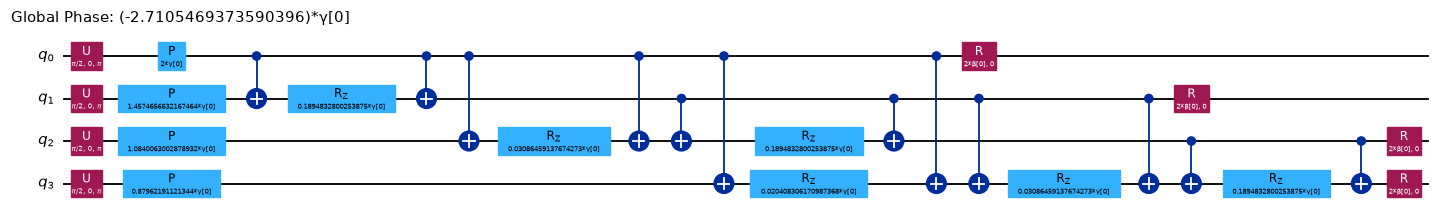

In [6]:
d = inst["main_12"]
H, offset = ww.qubo_to_ising(d["lin"], d["W"])
scale = np.abs(H.coeffs).max()
Hn = H / scale                      # normalized for training; same minimizer
print(f"Hamiltonian on {H.num_qubits} qubits: {sum(1 for p in H.paulis if str(p).count('Z') == 1)} Z terms, "
      f"{sum(1 for p in H.paulis if str(p).count('Z') == 2)} ZZ terms; |coefficient| max {scale:,.1f}, offset {offset:,.1f} MWh/yr")
diag = H.to_matrix(sparse=True).diagonal().real + offset
assert np.allclose(diag, d["values"]), "Ising energies must equal QUBO values"
print("check passed: <x|H|x> + offset equals the QUBO value for all 4,096 layouts")
print("12-qubit p=1 circuit, gate counts after one decomposition:", dict(ww.qaoa_circuit(Hn, 1).decompose().count_ops()))
H4, _ = ww.qubo_to_ising(d["lin"][:4], d["W"][:4, :4])   # 4-site slice, only to show the circuit structure
ww.qaoa_circuit(H4 / np.abs(H4.coeffs).max(), 1).decompose().draw("mpl", fold=-1, scale=0.6)

## 5. QAOA on the 12-site instance (noiseless simulation)

First the $p=1$ energy landscape over $(\gamma, \beta)$, evaluated exactly with `StatevectorEstimator`, then trained circuits at depth $p = 1, 2, 3$ sampled 10,000 times each.

trained p=1 angles: gamma = -0.684, beta = 3.515


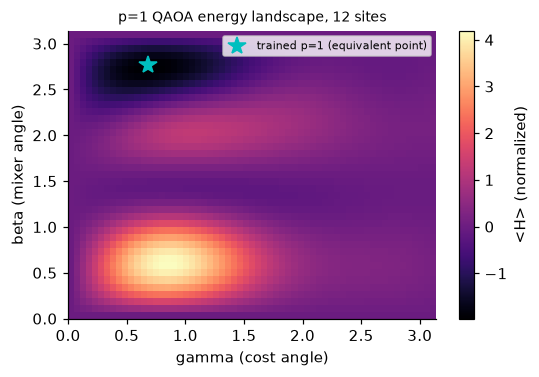

,P(opt),P(opt) within 100 shots,P(sample beats greedy),gap closed,N95 shots
method,,,,,
uniform random (control),0.02%,2%,1.4%,0.00,"12,269"
QAOA p=1 (ideal),0.30%,26%,11.0%,0.47,997
QAOA p=2 (ideal),0.81%,56%,19.5%,0.58,368
QAOA p=3 (ideal),1.26%,72%,25.9%,0.62,236
greedy planner (one deterministic answer),0.00%,0%,0.0%,0.76,inf


In [7]:
from qiskit.primitives import StatevectorEstimator
ans1 = ww.qaoa_circuit(Hn, 1)                       # parameters ordered [beta, gamma]
gammas, betas = np.linspace(0, np.pi, 61), np.linspace(0, np.pi, 41)   # e^{-i beta sum X} has period pi in beta
grid_params = np.array([[b, g] for b in betas for g in gammas])
landscape = StatevectorEstimator().run([(ans1, Hn, grid_params)]).result()[0].data.evs.reshape(len(betas), len(gammas))

qaoa = {}
for p in [1, 2, 3]:
    ans = ww.qaoa_circuit(Hn, p)
    best, start_values = ww.train_qaoa(ans, Hn, starts=5, seed=SEED_STARTS)
    counts = ww.ideal_counts(ans, best.x, shots=SHOTS_IDEAL, seed=SEED_SAMPLER)
    qaoa[p] = dict(params=best.x, energy=best.fun, starts=start_values, counts=counts,
                   **ww.summarize(counts, d["lin"], d["W"], d["f_opt"], d["f_rand"]))

fig, ax = plt.subplots(figsize=(5.4, 3.4))
im = ax.imshow(landscape, origin="lower", aspect="auto", extent=[0, np.pi, 0, np.pi], cmap="magma")
b1, g1 = qaoa[1]["params"]
print(f"trained p=1 angles: gamma = {g1:.3f}, beta = {b1:.3f}")
if g1 < 0:                      # H is real, so (gamma, beta) and (-gamma, -beta) give the same energy
    g1, b1 = -g1, -b1
if 0 <= g1 <= np.pi:
    ax.plot(g1, b1 % np.pi, "c*", ms=12, label="trained p=1 (equivalent point)")
ax.set_xlabel("gamma (cost angle)"); ax.set_ylabel("beta (mixer angle)"); ax.legend(fontsize=7, loc="upper right")
fig.colorbar(im, label="<H> (normalized)"); ax.set_title("p=1 QAOA energy landscape, 12 sites", fontsize=9)
fig.savefig(FIG / "landscape.png", bbox_inches="tight"); plt.show()

n12 = 12
n_opt_states = int(np.isclose(d["values"], d["f_opt"]).sum())
p_rand = n_opt_states / 2 ** n12
n95 = lambda p: np.log(0.05) / np.log1p(-p) if p > 0 else np.inf
def beats_greedy(counts):
    states = np.array([int(s) for s in counts]); w = np.array(list(counts.values()), float)
    return float(w[d["values"][states] < d["f_gr"] - 1e-9].sum() / w.sum())

rows = [{"method": "uniform random (control)", "P(opt)": p_rand, "P(opt) within 100 shots": 1 - (1 - p_rand) ** 100,
         "P(sample beats greedy)": float((d["values"] < d["f_gr"] - 1e-9).mean()), "gap closed": 0.0, "N95 shots": n95(p_rand)}]
for p, r in qaoa.items():
    rows.append({"method": f"QAOA p={p} (ideal)", "P(opt)": r["p_opt"], "P(opt) within 100 shots": 1 - (1 - r["p_opt"]) ** 100,
                 "P(sample beats greedy)": beats_greedy(r["counts"]), "gap closed": r["gap_closed"], "N95 shots": n95(r["p_opt"])})
rows.append({"method": "greedy planner (one deterministic answer)", "P(opt)": 0.0, "P(opt) within 100 shots": 0.0,
             "P(sample beats greedy)": 0.0, "gap closed": (d["f_rand"] - d["f_gr"]) / (d["f_rand"] - d["f_opt"]), "N95 shots": np.inf})
ideal_table = pd.DataFrame(rows).set_index("method")
ideal_table.style.format({"P(opt)": "{:.2%}", "P(opt) within 100 shots": "{:.0%}", "P(sample beats greedy)": "{:.1%}",
                          "gap closed": "{:.2f}", "N95 shots": "{:,.0f}"})

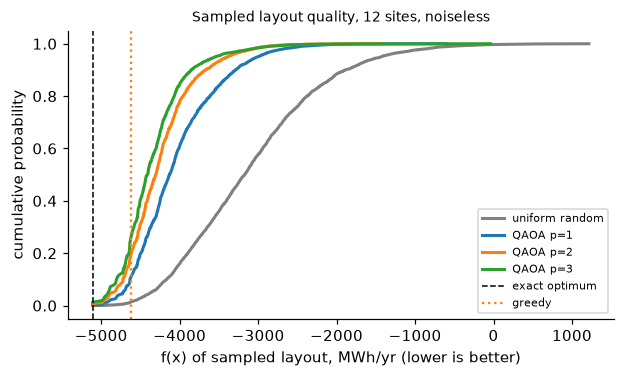

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
v_sorted = np.sort(d["values"])
ax.plot(v_sorted, np.arange(1, len(v_sorted) + 1) / len(v_sorted), color="gray", lw=2, label="uniform random")
for p, r in qaoa.items():
    states = np.array([int(s) for s in r["counts"]]); w = np.array(list(r["counts"].values()), float)
    v = d["values"][states]; o = np.argsort(v)
    ax.plot(v[o], np.cumsum(w[o]) / w.sum(), lw=2, label=f"QAOA p={p}")
ax.axvline(d["f_opt"], color="k", ls="--", lw=1, label="exact optimum")
ax.axvline(d["f_gr"], color="tab:orange", ls=":", lw=1.5, label="greedy")
ax.set_xlabel("f(x) of sampled layout, MWh/yr (lower is better)"); ax.set_ylabel("cumulative probability")
ax.set_title("Sampled layout quality, 12 sites, noiseless", fontsize=9); ax.legend(fontsize=7)
fig.savefig(FIG / "distributions.png", bbox_inches="tight"); plt.show()

## 6. Noise and real hardware (9-site instance)

Each $ZZ$ term costs two-qubit gates, and IBM's heavy-hex chips connect each qubit to at most three neighbours, so dense couplings also cost SWAPs. We therefore compare the full Hamiltonian with a **sparsified** one that keeps only couplings at least 25% as strong as the strongest (sampled layouts are still scored with the *full* QUBO, so any harm from sparsifying shows up in the metrics). Circuits:

1. `p1_full`: $p=1$, all 36 couplings
2. `p1_sparse`: $p=1$, couplings $\geq 25\%$ of max
3. `p2_sparse`: $p=2$, couplings $\geq 25\%$ of max
4. `control_uniform`: the same ansatz with $\gamma=\beta=0$, which should give uniformly random layouts; on hardware it measures the noise floor

All are trained in noiseless simulation (no QPU time spent on training), then executed three ways: ideal statevector, `FakeFez` noisy simulation, and an IBM Heron device. Sampler options: dynamical decoupling (XY4) and gate twirling.

In [9]:
from qiskit_ibm_runtime.fake_provider import FakeFez
h = inst["hw_9"]
W_sparse = ww.sparsify(h["W"], 0.25)
xs_opt, _, _ = ww.exact(h["lin"], W_sparse)
print(f"9 sites: {np.count_nonzero(np.triu(h['W'], 1))} couplings in full model, {np.count_nonzero(np.triu(W_sparse, 1))} after sparsifying; "
      f"the sparse model's own optimum scores {ww.qubo_values(xs_opt, h['lin'], h['W'])[0]:,.0f} on the full QUBO (true optimum {h['f_opt']:,.0f})")

# Same function the hardware run uses (`python wakewise.py hardware`), so the circuits are identical.
hw_circuits, hw_names, hw_params = ww.hardware_circuits(h["lin"], h["W"], keep=0.25, starts=5, seed=SEED_STARTS)

score = lambda c: ww.summarize(c, h["lin"], h["W"], h["f_opt"], h["f_rand"])
ideal_hw = {nm: score(ww.ideal_counts(qc.copy(), [], shots=SHOTS_IDEAL, seed=SEED_SAMPLER))
            for nm, qc in zip(hw_names, hw_circuits)}
noisy = ww.run_sampler(hw_circuits, FakeFez(), shots=SHOTS_DEVICE, seed=SEED_NOISE, names=hw_names,
                       meta=dict(instance="hw_9", params=hw_params), out=ww.RESULTS / "fakefez_9site.json")

9 sites: 36 couplings in full model, 19 after sparsifying; the sparse model's own optimum scores -4,548 on the full QUBO (true optimum -4,718)


In [10]:
hw_file = ww.RESULTS / "hardware_9site.json"   # written by `python wakewise.py hardware` or by RUN_HARDWARE=1
if RUN_HARDWARE:
    backend = ww.hardware_backend()
    print("running on", backend.name, "...")
    ww.run_sampler(hw_circuits, backend, shots=SHOTS_DEVICE, names=hw_names,
                   meta=dict(instance="hw_9", params=hw_params), out=hw_file)
hardware = json.loads(hw_file.read_text()) if hw_file.exists() else None
if hardware:
    keep = {k: hardware[k] for k in ["backend", "job_id", "utc", "shots", "usage_s", "calibration", "options"]}
    print(json.dumps(keep, indent=1))
else:
    print("No saved hardware results yet: hardware columns below are empty.")

def tvd_uniform(counts, n=9):
    p = np.zeros(2 ** n)
    for s, c in counts.items(): p[int(s)] += c
    return 0.5 * np.abs(p / p.sum() - 1 / 2 ** n).sum()

rows = []
for k, nm in enumerate(hw_names):
    r = {"circuit": nm, "2q gates (Heron)": noisy["circuits"][k]["two_qubit_gates"], "depth": noisy["circuits"][k]["depth"],
         "ideal P(opt)": ideal_hw[nm]["p_opt"], "ideal gap": ideal_hw[nm]["gap_closed"]}
    s = score(noisy["counts"][k]); r.update({"FakeFez P(opt)": s["p_opt"], "FakeFez gap": s["gap_closed"]})
    if hardware:
        s = score(hardware["counts"][k])
        r.update({"hardware P(opt)": s["p_opt"], "hardware gap": s["gap_closed"],
                  "hardware 2q gates": hardware["circuits"][k]["two_qubit_gates"]})
    rows.append(r)
hw_table = pd.DataFrame(rows).set_index("circuit")
p_rand9 = np.isclose(h["values"], h["f_opt"]).sum() / 2 ** 9
print(f"uniform random control: P(opt) = {p_rand9:.2%}, gap closed = 0 by definition")
if hardware:
    draws = np.random.default_rng(0).integers(0, 2 ** 9, (20, SHOTS_DEVICE))
    floor = np.mean([tvd_uniform(dict(zip(*np.unique(row, return_counts=True)))) for row in draws])
    print(f"control circuit, total variation distance from uniform: hardware {tvd_uniform(hardware['counts'][3]):.3f}, "
          f"FakeFez {tvd_uniform(noisy['counts'][3]):.3f}, perfect sampler with {SHOTS_DEVICE} shots {floor:.3f}")
hw_table.style.format({c: "{:.2%}" for c in hw_table.columns if "P(opt)" in c} | {c: "{:.2f}" for c in hw_table.columns if "gap" in c})

No saved hardware results yet: hardware columns below are empty.
uniform random control: P(opt) = 0.20%, gap closed = 0 by definition


,2q gates (Heron),depth,ideal P(opt),ideal gap,FakeFez P(opt),FakeFez gap
circuit,,,,,,
p1_full,144,275,1.86%,0.45,1.30%,0.39
p1_sparse,64,141,1.34%,0.44,1.12%,0.41
p2_sparse,146,271,2.16%,0.57,1.98%,0.51
control_uniform,0,4,0.15%,0.01,0.18%,0.01


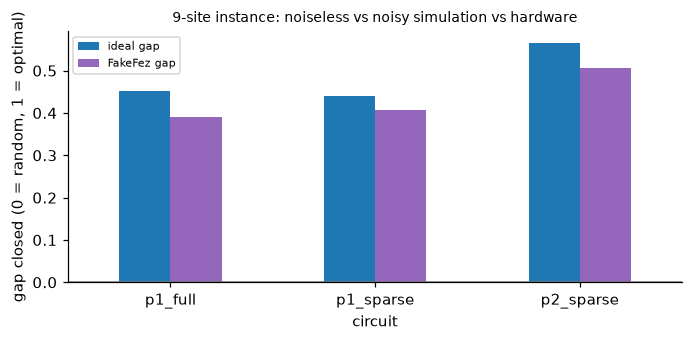

In [11]:
cols = [c for c in ["ideal gap", "FakeFez gap", "hardware gap"] if c in hw_table.columns]
ax = hw_table.loc[hw_names[:3], cols].plot.bar(figsize=(6.4, 3.2), rot=0, color=["tab:blue", "tab:purple", "tab:green"][:len(cols)])
ax.axhline(0, color="gray", lw=1)
ax.set_ylabel("gap closed (0 = random, 1 = optimal)"); ax.set_title("9-site instance: noiseless vs noisy simulation vs hardware", fontsize=9)
ax.legend(fontsize=7); plt.tight_layout(); plt.savefig(FIG / "noise_hardware.png", bbox_inches="tight"); plt.show()

## 7. Model check: is the pairwise wake approximation good enough to rank layouts?

The QUBO adds wake losses pair by pair. A more realistic model combines all upstream wakes on a turbine as the root-sum-square of their speed deficits (not pairwise, so not a QUBO). If the QUBO ranks layouts the same way as this richer model, then optimizing the QUBO is meaningful.

In [12]:
from scipy.stats import spearmanr
d = inst["main_12"]
_, _, info = ww.build_qubo(d["xy"], wd, u)
order = np.argsort(d["values"])
rng = np.random.default_rng(0)
check = np.unique(np.concatenate([order[:60], rng.choice(4096, 140, replace=False)]))
X = ww.bits(check, 12)
net_multi = np.array([ww.layout_aep(x, d["xy"], wd, u) - info["cost"] @ x for x in X])
net_pair = -d["values"][check]
rho = spearmanr(net_pair, net_multi)[0]
best_multi = check[np.argmax(net_multi)]
opt_state = int(np.argmin(d["values"]))
print(f"{len(check)} layouts (60 best by QUBO + 140 random): Spearman rank correlation pairwise vs multi-wake = {rho:.3f}")
print(f"QUBO optimum is {'also' if best_multi == opt_state else 'NOT'} the best of these under the multi-wake model; "
      f"its net value: pairwise {-d['f_opt']:,.0f} vs multi-wake {net_multi[check == opt_state][0]:,.0f} MWh/yr")

195 layouts (60 best by QUBO + 140 random): Spearman rank correlation pairwise vs multi-wake = 0.992
QUBO optimum is also the best of these under the multi-wake model; its net value: pairwise 5,105 vs multi-wake 5,158 MWh/yr


## 8. Results summary and what the evidence supports

In [13]:
d, h = inst["main_12"], inst["hw_9"]
lines = [
    f"Real input: {len(u):,} hours of 2025 Wreckhouse wind; one turbine alone yields {E:,.0f} MWh/yr; "
    f"one neighbour can cost up to {Wm.max():,.0f} MWh/yr ({Wm.max() / E:.1%}).",
    f"Classical: the exact optimum on 12 sites builds {int(d['x_opt'].sum())} turbines (f* = {d['f_opt']:,.0f} MWh/yr); "
    f"greedy is {(d['f_gr'] - d['f_opt']) / abs(d['f_opt']):.1%} worse; uniform random averages {d['f_rand']:,.0f}.",
    "Quantum (noiseless, 12 qubits): " + "; ".join(
        f"p={p}: P(opt) {r['p_opt']:.2%} ({r['p_opt'] / p_rand:.0f}x random), gap closed {r['gap_closed']:.2f}"
        for p, r in qaoa.items()) + f". Shots to see the optimum with 95% confidence: {n95(qaoa[3]['p_opt']):,.0f} (p=3) vs {n95(p_rand):,.0f} (random). "
    f"At p=3, {ideal_table.loc['QAOA p=3 (ideal)', 'P(sample beats greedy)']:.0%} of samples beat the greedy layout, but the average sample "
    f"(gap closed {qaoa[3]['gap_closed']:.2f}) is below greedy's single answer ({ideal_table.iloc[-1]['gap closed']:.2f}).",
    "Noise (9 qubits, FakeFez): " + "; ".join(
        f"{nm}: gap closed {hw_table.loc[nm, 'ideal gap']:.2f} ideal -> {hw_table.loc[nm, 'FakeFez gap']:.2f} noisy"
        for nm in hw_names[:3]) + ".",
]
if hardware:
    lines.append(f"Hardware ({hardware['backend']}, job {hardware['job_id']}): " + "; ".join(
        f"{nm}: gap closed {hw_table.loc[nm, 'hardware gap']:.2f}, P(opt) {hw_table.loc[nm, 'hardware P(opt)']:.2%}"
        for nm in hw_names[:3]) + f" (random P(opt) = {p_rand9:.2%}).")
lines.append(f"Model check: pairwise QUBO vs multi-wake ranking, Spearman {rho:.3f}.")
print("\n".join("- " + s for s in lines))

# Single source of truth for the slides: every number quoted in the deck comes from this file.
fl = lambda v: None if v is None or (isinstance(v, float) and not np.isfinite(v)) else float(v)
summary = dict(
    hours=len(u), mean_hub_ms=fl(u.mean()), E=fl(E), capacity_factor=fl(E / (4 * 8760)),
    max_pair_loss=fl(Wm.max()), max_pair_loss_frac=fl(Wm.max() / E), spearman=fl(rho),
    main=dict(sites=12, f_opt=fl(d["f_opt"]), turbines=int(d["x_opt"].sum()), f_greedy=fl(d["f_gr"]),
              greedy_gap=fl((d["f_gr"] - d["f_opt"]) / abs(d["f_opt"])), f_random=fl(d["f_rand"]),
              greedy_gap_closed=fl(ideal_table.iloc[-1]["gap closed"])),
    hw9=dict(sites=9, f_opt=fl(h["f_opt"]), turbines=int(h["x_opt"].sum()),
             greedy_gap=fl((h["f_gr"] - h["f_opt"]) / abs(h["f_opt"])), p_opt_random=fl(p_rand9)),
    sensitivity=sens,
    random=dict(p_opt=fl(p_rand), n95=fl(n95(p_rand)), within100=fl(1 - (1 - p_rand) ** 100),
                beats_greedy=fl(ideal_table.iloc[0]["P(sample beats greedy)"])),
    qaoa={str(p): dict(p_opt=fl(r["p_opt"]), gap_closed=fl(r["gap_closed"]), n95=fl(n95(r["p_opt"])),
                       within100=fl(1 - (1 - r["p_opt"]) ** 100),
                       beats_greedy=fl(ideal_table.loc[f"QAOA p={p} (ideal)", "P(sample beats greedy)"]))
          for p, r in qaoa.items()},
    noise={nm: {k: fl(v) for k, v in hw_table.loc[nm].items()} for nm in hw_names},
    hardware=None if not hardware else {k: hardware[k] for k in ["backend", "job_id", "utc", "shots", "usage_s", "calibration"]},
)
(ww.RESULTS / "summary.json").write_text(json.dumps(summary, indent=1))
print("saved results/summary.json")

- Real input: 8,740 hours of 2025 Wreckhouse wind; one turbine alone yields 13,993 MWh/yr; one neighbour can cost up to 613 MWh/yr (4.4%).
- Classical: the exact optimum on 12 sites builds 6 turbines (f* = -5,105 MWh/yr); greedy is 9.6% worse; uniform random averages -3,087.
- Quantum (noiseless, 12 qubits): p=1: P(opt) 0.30% (12x random), gap closed 0.47; p=2: P(opt) 0.81% (33x random), gap closed 0.58; p=3: P(opt) 1.26% (52x random), gap closed 0.62. Shots to see the optimum with 95% confidence: 236 (p=3) vs 12,269 (random). At p=3, 26% of samples beat the greedy layout, but the average sample (gap closed 0.62) is below greedy's single answer (0.76).
- Noise (9 qubits, FakeFez): p1_full: gap closed 0.45 ideal -> 0.39 noisy; p1_sparse: gap closed 0.44 ideal -> 0.41 noisy; p2_sparse: gap closed 0.57 ideal -> 0.51 noisy.
- Model check: pairwise QUBO vs multi-wake ranking, Spearman 0.992.
saved results/summary.json


**What the evidence supports**

* The siting problem is genuinely combinatorial on real NL wind data: a sensible greedy planner misses several percent of achievable net energy, because wake interactions couple the choices.
* QAOA, implemented with Qiskit, turns the wake Hamiltonian into a sampler that is strongly biased toward good layouts: in noiseless simulation it raises the chance of drawing the optimal layout 12x (p=1) to about 50x (p=3) over random guessing, and quality improves with depth $p$. Used as a sampler, a few hundred shots are enough to find the optimal layout that greedy misses.
* Honest caveat: QAOA's *average* sample is still worse than the greedy planner's single answer; its value here is in the best of its samples, not in a typical one. Deeper circuits, better training or warm starts would be needed to change that.
* Under a realistic Heron noise model the signal degrades but survives at these sizes; sparsifying weak couplings roughly halves the two-qubit gate count and helps under noise, at a small cost in model fidelity.
* What it does **not** support: any claim of quantum advantage. A laptop enumerates all layouts here. These results are a verified proof of concept of the pipeline and its behaviour, within the tested conditions (one year of wind, idealized flat parcel, illustrative costs).

## 9. Limitations, assumptions, resources and next steps

* **Model:** flat terrain, one wind year, 10 m data extrapolated to hub height, a generic turbine and Jensen wake model, and costs expressed as energy are all simplifications. Pairwise wake superposition is checked against a multi-wake model (Section 7) but not against field data or high-fidelity flow models.
* **Quantum:** QAOA depth $p \le 3$, trained in noiseless simulation; COBYLA occasionally stalls from poor starts, hence several starts. On hardware, dense couplings need many SWAPs on heavy-hex connectivity, which is why the hardware instance is 9 sites and why we test sparsification.
* **Resources:** each noiseless experiment takes seconds on a laptop; the full notebook runs in a few minutes. Hardware: one job of 4 circuits x 4,000 shots (QPU usage recorded in `results/hardware_9site.json`).
* **Next steps:** real parcel geometry and terrain-aware wind (e.g., WRF or NASA POWER at 50 m) for the Codroy Valley; minimum-spacing and exclusion constraints (wetlands, caribou habitat) as extra QUBO terms; constraint-preserving mixers and warm starts; larger instances where exact enumeration stops being possible and QAOA must be compared with strong classical heuristics (simulated annealing, MILP). A natural home is MUN's CREATE-SWIFT program, with Mitacs Accelerate as a route to an industry partner.

## 10. Credits and team contribution

* **Reused and adapted:** the QAOA workflow pattern (QUBO -> Ising -> ansatz -> Estimator + COBYLA -> Sampler) from Tinh Bui's *Quantum Optimization* workshop notebook (Qiskit Fall Fest 2026), whose brute-force answer selection we deliberately replace with selection from samples; IBM runtime setup and Sampler options from the *Qiskit 101* hands-on notebook (IBM, Apache 2.0); Qiskit, Qiskit Aer and Qiskit IBM Runtime (Apache 2.0); NumPy, SciPy, pandas, Matplotlib.
* **Data:** Environment and Climate Change Canada hourly climate data (Open Government Licence, Canada).
* **Methods from the literature:** Jensen (1983) and Katic, Højstrup and Jensen (1986) wake model; Farhi, Goldstone and Gutmann (2014) QAOA; prior QUBO formulations of wind-farm layout (e.g., Senderovich et al., 2022, quantum annealing for turbine layout) inspired the pairwise wake encoding.
* **Our contribution:** the problem framing for NL's west coast, the hour-by-hour wake-loss QUBO built from real Wreckhouse data, the validation design (exact, greedy and random baselines on the same instances, multi-wake model check, sparsification study, control circuit), all code in `wakewise.py`, the tests, and the experiments and their interpretation. AI tools (Claude) assisted with code and writing; the team reviewed and can explain every part.